# **Load data and packages for project**

In [4]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load dataset
DATA_PATH = "kennedy_golf_reviews.csv"
df = pd.read_csv(DATA_PATH)

print(f"Total records: {len(df)}")
display(df.head())

Total records: 733


,review_text,star_rating,course_name,review_date,location
0,I played the west nine a number of times and e...,5,Kennedy Golf Course,2026-10-27T11:41:35.214Z,"Denver, CO"
1,Great local course,5,Kennedy Golf Course,2026-10-18T02:15:14.888Z,"Denver, CO"
2,I played the par 3 course with a friend. We s...,5,Kennedy Golf Course,2026-09-27T04:37:12.017Z,"Denver, CO"
3,"Just played there, took 5 hours to play 16 hol...",1,Kennedy Golf Course,2026-09-20T22:37:19.961Z,"Denver, CO"
4,Great day with the QC club.,4,Kennedy Golf Course,2026-09-12T16:09:05.372Z,"Denver, CO"


### **Basic Dataset Stats & Profiling**

DATASET OVERVIEW:
Shape: (733, 5)

MISSING VALUES:
review_text    0
star_rating    0
course_name    0
review_date    0
location       0
dtype: int64

DATA TYPES:
review_text    object
star_rating     int64
course_name    object
review_date    object
location       object
dtype: object

--- STAR RATING DISTRIBUTION ---
star_rating
1     51
2     30
3     56
4    208
5    388
Name: count, dtype: int64


/tmp/ipykernel_2396/4192667557.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="crest")


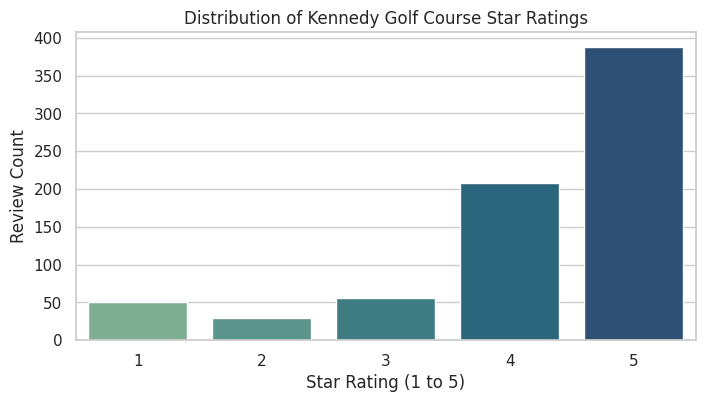

In [7]:
print("DATASET OVERVIEW:")
print(f"Shape: {df.shape}")
print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDATA TYPES:")
print(df.dtypes)

# Target / Star Rating Distribution
print("\n--- STAR RATING DISTRIBUTION ---")
rating_counts = df["star_rating"].value_counts().sort_index()
print(rating_counts)

# Plot Star Rating Distribution
plt.figure(figsize=(8, 4))
sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="crest")
plt.title("Distribution of Kennedy Golf Course Star Ratings")
plt.xlabel("Star Rating (1 to 5)")
plt.ylabel("Review Count")
plt.show()

TEXT LENGTH SUMMARY STATS:
       char_length  word_count
count   733.000000  733.000000
mean    130.780355   24.462483
std     211.812719   40.342018
min       2.000000    1.000000
25%      29.000000    5.000000
50%      67.000000   12.000000
75%     143.000000   27.000000
max    3056.000000  597.000000


/tmp/ipykernel_2396/2692176575.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


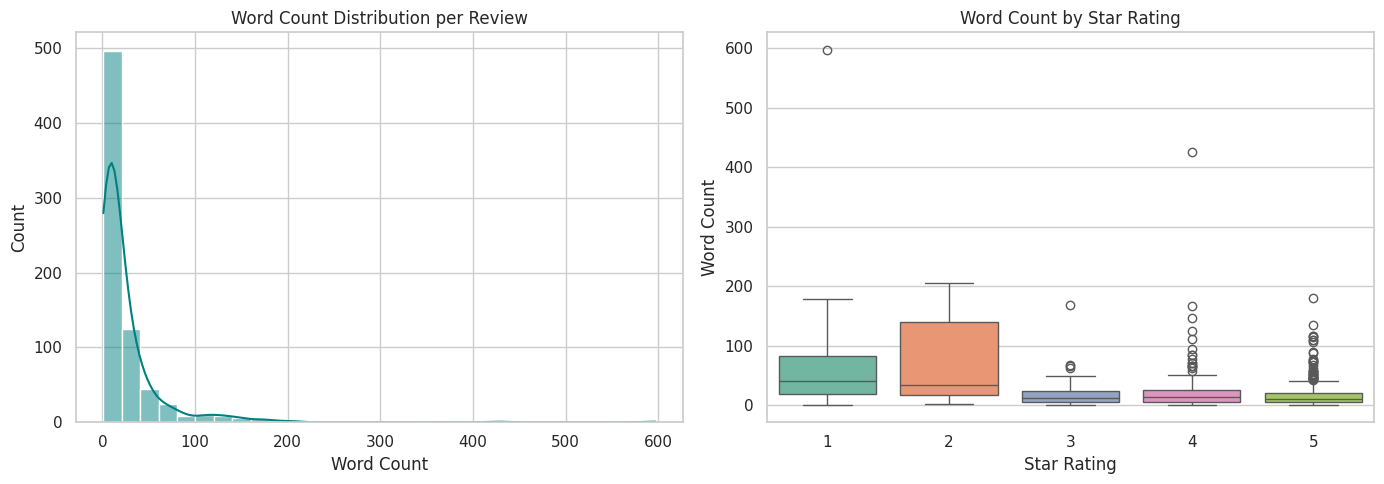


SAMPLE SHORT VS LONG REVIEWS:

1-Star Sample Review:
Just played there, took 5 hours to play 16 holes . We bailed on the last two holes because of the slow pace and no Marshall’s keeping it going. It was nearly 90 degrees out and the beverage cart was seen one time in our entire round. The older gentleman at check in was extremely rude too....

5-Star Sample Review:
I played the west nine a number of times and enjoyed walking the course. I have also played the creek nine as we ell,...


In [8]:
# Character length and word count features
df["char_length"] = df["review_text"].astype(str).apply(len)
df["word_count"] = (
    df["review_text"].astype(str).apply(lambda x: len(x.split()))
)

print("TEXT LENGTH SUMMARY STATS:")
print(df[["char_length", "word_count"]].describe())

# Visualizing Text Length Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["word_count"], kde=True, ax=axes[0], color="teal", bins=30
)
axes[0].set_title("Word Count Distribution per Review")
axes[0].set_xlabel("Word Count")

sns.boxplot(
    x="star_rating", y="word_count", data=df, ax=axes[1], palette="Set2"
)
axes[1].set_title("Word Count by Star Rating")
axes[1].set_xlabel("Star Rating")
axes[1].set_ylabel("Word Count")

plt.tight_layout()
plt.show()

# Sample reviews across ratings
print("\nSAMPLE SHORT VS LONG REVIEWS:")
print("\n1-Star Sample Review:")
print(
    df[df["star_rating"] == 1]["review_text"].iloc[0][:300]
    + "..."
)
print("\n5-Star Sample Review:")
print(
    df[df["star_rating"] == 5]["review_text"].iloc[0][:300]
    + "..."
)

### **Text Mining Basics**

**Keyword and N-Gram Frequency Analysis**

/tmp/ipykernel_2396/2044157119.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


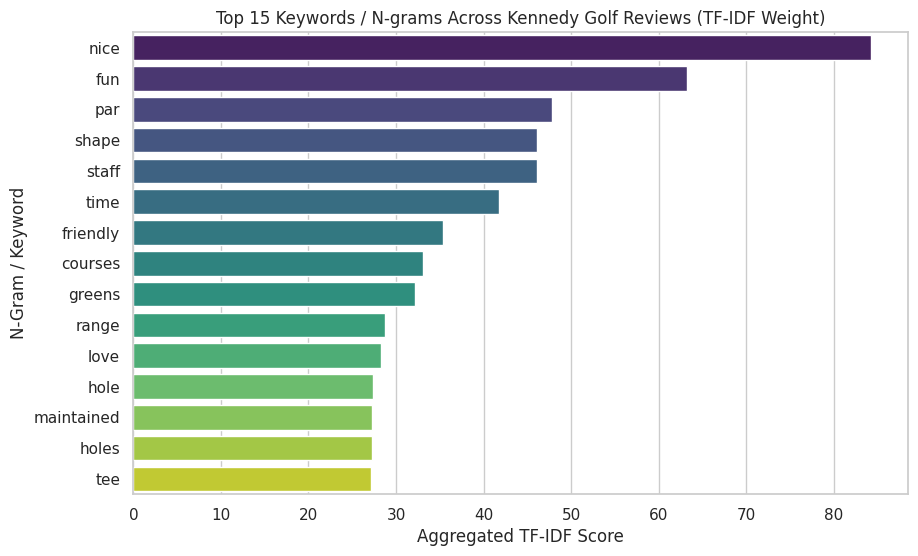

In [10]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

# Basic cleaning for frequency counting
def clean_text(text):
  text = str(text).lower()
  text = re.sub(r"[^a-z\s]", "", text)
  text = re.sub(r"\s+", " ", text).strip()
  return text


df["cleaned_text"] = df["review_text"].apply(clean_text)

# Add golf stop words
golf_stopwords = list(ENGLISH_STOP_WORDS) + [
    "golf",
    "course",
    "play",
    "played",
    "kennedy",
    "denver",
    "place",
    "great",
    "good",
    "like",
    "just",
]

# Unigram & Bigram Extraction
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), stop_words=golf_stopwords, max_features=20
)
tfidf_matrix = vectorizer.fit_transform(df["cleaned_text"])
feature_names = vectorizer.get_feature_names_out()
tfidf_scores = tfidf_matrix.sum(axis=0).A1

freq_df = (
    pd.DataFrame({"ngram": feature_names, "tfidf_sum": tfidf_scores})
    .sort_values(by="tfidf_sum", ascending=False)
)

# Plot top n-grams
plt.figure(figsize=(10, 6))
sns.barplot(
    x="tfidf_sum", y="ngram", data=freq_df.head(15), palette="viridis"
)
plt.title("Top 15 Keywords / N-grams Across Kennedy Golf Reviews (TF-IDF Weight)")
plt.xlabel("Aggregated TF-IDF Score")
plt.ylabel("N-Gram / Keyword")
plt.show()

**Baseline Lexicon Sentiment Analysis (VADER)**

/tmp/ipykernel_2396/395534862.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


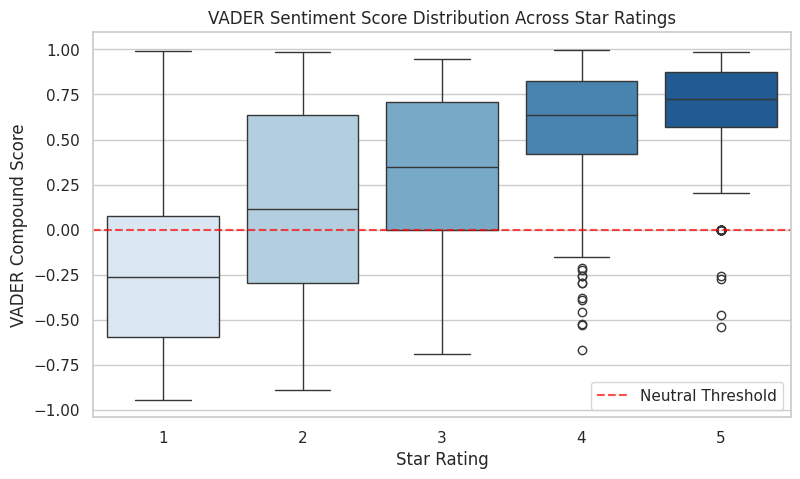


Number of low-star reviews (1-2 stars) with high VADER sentiment (>0.5): 19

Sample Lexicon Mismatch:
Rating: 2 | Text: Poor course conditions,  not really due to the heavy rains but due to a lot of dead grass areas and poor over all maintenance.   I have never seen so many broken tees on tee boxes.   Clean up your course better,  that includes tee boxes.   The starte...


In [11]:
import nltk

nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

# Calculate VADER sentiment score
df["vader_compound"] = df["review_text"].apply(
    lambda x: sia.polarity_scores(str(x))["compound"]
)

# Visualize VADER vs Star Rating
### AI USAGE NOTE 1####
plt.figure(figsize=(9, 5))
sns.boxplot(
    x="star_rating", y="vader_compound", data=df, palette="Blues"
)
plt.title("VADER Sentiment Score Distribution Across Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("VADER Compound Score")
plt.axhline(0, color="red", linestyle="--", alpha=0.7, label="Neutral Threshold")
plt.legend()
plt.show()

# Highlight mismatch/limitation cases (e.g., negative rating with high sentiment)
mismatches = df[(df["star_rating"] <= 2) & (df["vader_compound"] > 0.5)]
print(
    f"\nNumber of low-star reviews (1-2 stars) with high VADER sentiment (>0.5): {len(mismatches)}"
)
print("\nSample Lexicon Mismatch:")
if len(mismatches) > 0:
  print(
      f"Rating: {mismatches.iloc[0]['star_rating']} | Text:"
      f" {mismatches.iloc[0]['review_text'][:250]}..."
  )

# **Topic Extraction**

Moving beyond generic word frequencies, this step uses rule-based keyword flagging to map reviews directly to core business operations. Examples include: pace of play, course condition, staff service, and value.

Aggregating these domain-specific keywords establishes an initial baseline of how frequently players experience specific operational pain points. This preliminary breakdown provides a structured framework that directly informs the aspect-based sentiment extraction planned for Phase 3.



/tmp/ipykernel_2396/3545049629.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'flag_{topic}'] = df['cleaned_text'].str.contains(pattern, case=False, regex=True).astype(int)
/tmp/ipykernel_2396/3545049629.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'flag_{topic}'] = df['cleaned_text'].str.contains(pattern, case=False, regex=True).astype(int)
/tmp/ipykernel_2396/3545049629.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'flag_{topic}'] = df['cleaned_text'].str.contains(pattern, case=False, regex=True).astype(int)
/tmp/ipykernel_2396/3545049629.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[f'flag_{

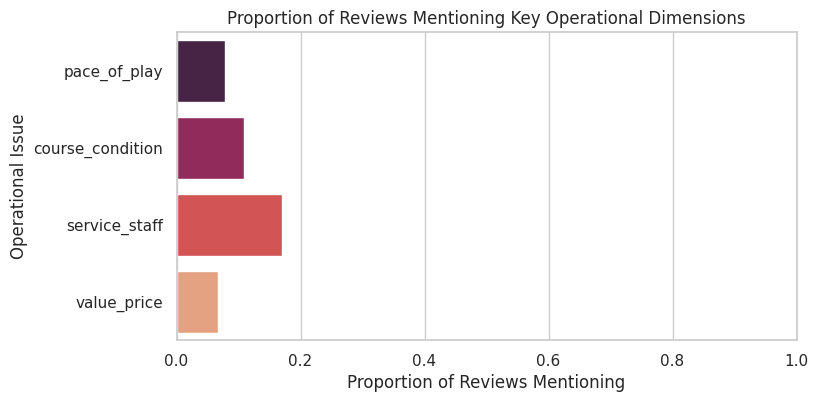

In [12]:
# Simple rule-based topic flags
operational_keywords = {
    "pace_of_play": ["pace", "slow", "wait", "hours", "backed up", "waiting", "marshal"],
    "course_condition": ["greens", "fairways", "bunkers", "sand", "grass", "dirt", "mud"],
    "service_staff": ["staff", "pro shop", "rude", "starter", "service", "cart boy"],
    "value_price": ["price", "cost", "expensive", "deal", "worth", "rates"]
}

for topic, words in operational_keywords.items():
    pattern = r'\b(' + '|'.join(words) + r')\b'
    df[f'flag_{topic}'] = df['cleaned_text'].str.contains(pattern, case=False, regex=True).astype(int)

# Calculate frequency of operational flags
flag_cols = [c for c in df.columns if c.startswith('flag_')]
flag_summary = df[flag_cols].mean().reset_index()
flag_summary.columns = ['Operational Issue', 'Proportion of Reviews Mentioning']
flag_summary['Operational Issue'] = flag_summary['Operational Issue'].str.replace('flag_', '')

plt.figure(figsize=(8, 4))
sns.barplot(x='Proportion of Reviews Mentioning', y='Operational Issue', data=flag_summary, palette='rocket')
plt.title("Proportion of Reviews Mentioning Key Operational Dimensions")
plt.xlim(0, 1)
plt.show()

## **AI Usage Disclosure**

NOTE 1: I used Gemini to refine the comparative analysis between the lexicon-based VADER sentiment scores and the actual raw star ratings. Specifically, Gemini assisted by suggesting and writing the Python code for a dual-output comparison visualization (such as scatter/box plots with ideal alignment lines) to clearly contrast predicted sentiment ratings alongside the users' actual star ratings.In prompting the output to show both on seperate axis Gemini output a chart that contain both data points correctly and clearly visualized. I inspected the selected input fields to confirm the fields utilized appeared reasonable.

## Part 3: Plan for Phase 3

### 1. Selected Path: Path B (Structured Information Extraction & Explanation)
I plan to switch to **Path B (Explanatory/Information Extraction)** rather than Path A after reviwing the feedback given on my orginal project plan.
* **Business Justification:** General Managers already know when a review is negative from its star rating. Predicting 1-3 vs. 4-5 stars yields zero operational value. Instead, management requires structured extraction of **what caused the negative experience** and **by how much each issue penalizes overall customer rating**.
* **Data Support:** The dataset includes timestamps (review_date), numeric ratings (star_rating), and rich textual feedback (review_text). This enables temporal segmentation (e.g., Q3 peak summer vs. shoulder season) alongside regression modeling of extracted aspect complaints against star ratings.

---

### 2. LLM Integration Strategy (Claude API Plan)
Rather than relying on noisy lexicon matching or uninterpretable TF-IDF n-grams, I will use the **Claude API** for structured aspect-based sentiment extraction offline.



**Practical Considerations & Risk Management**
Token Usage & API Cost: With ~743 reviews in the Kennedy Golf dataset, processing the full corpus will consume <$1 and process in only a few minutes.

**Result Validity & Hallucination Risk:** LLMs can occasionally misinterpret subtle domain context (e.g., confusing "lightning greens" as a hazard complaint rather than a compliment). We will validate a random sample of 50 LLM outputs against human labels to measure extraction accuracy before running our final regression models.

**Privacy & Compliance: **The review dataset contains public Google Maps reviews. No personal customer identifiers (PII), email addresses, or payment details are included in the API prompt payloads.

#### **Claude Task Specification:**
Claude will process each review and output a structured JSON object containing binary operational complaint flags and aspect-level sentiment scores:
* `pace_of_play_issue` (0 or 1)
* `course_condition_issue` (0 or 1)
* `staff_service_issue` (0 or 1)
* `pricing_value_issue` (0 or 1)
* `overall_primary_bottleneck` (Enum: `Pace`, `Greens/Turf`, `Staff`, `Value`, `None`)

#### **Sample Prompt Tested:**
```text
You are an expert golf operations analyst. Analyze the following customer review for a public golf course.
Extract the operational topics and determine if a specific issue is present.

Review Text: "{review_text}"

Return JSON strictly in this format:
{
  "pace_of_play_issue": 0 or 1,
  "course_condition_issue": 0 or 1,
  "staff_service_issue": 0 or 1,
  "pricing_value_issue": 0 or 1,
  "primary_bottleneck": "Pace" | "Condition" | "Service" | "Pricing" | "None",
  "explanation": "Brief 1-sentence summary of the main driver."
}